# Stock Return Prediction — AAPL Next-Day Log Return

**Research question:** Can ML models predict the *direction* of next-day returns better than a random walk?

**Design:** Stationary log-return target → 80+ features (technical indicators, rolling stats, calendar) → Ridge, Lasso, Huber, RF, GBM, XGBoost, LightGBM, MLP, Stacking, Weighted Ensemble. Walk-forward CV throughout.

**Key constraint:** Target = next-day **log return** (not price). Raw price gives R²≈0.98 via autocorrelation — that is not predictive signal. Direction accuracy > 52% is the real bar.


## 0. Imports

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, module='sklearn')
warnings.filterwarnings('ignore', category=UserWarning, module='lightgbm')
warnings.filterwarnings('ignore', category=FutureWarning, module='yfinance')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.stats import randint, uniform, loguniform

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet, HuberRegressor, LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.base import clone
import sklearn

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import lightgbm as lgb
import ta
import yfinance as yf

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight', 'font.size': 11})
sns.set_palette('husl')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
TSCV = TimeSeriesSplit(n_splits=5, gap=5)  # shared CV splitter; gap avoids leakage


## 1. Data Loading

Cached to CSV on first run to avoid yfinance rate limits. Multi-level columns (yfinance ≥0.2) flattened on download.


In [2]:
TICKER     = 'AAPL'
START_DATE = '2018-01-01'
END_DATE   = '2024-01-01'
CACHE_FILE = f'{TICKER}_{START_DATE[:4]}_{END_DATE[:4]}.csv'

if os.path.exists(CACHE_FILE):
    df_raw = pd.read_csv(CACHE_FILE, index_col=0, parse_dates=True)
else:
    df_raw = yf.download(TICKER, start=START_DATE, end=END_DATE, progress=False)
    if isinstance(df_raw.columns, pd.MultiIndex):
        df_raw.columns = df_raw.columns.get_level_values(0)
    df_raw.columns = ['Close', 'High', 'Low', 'Open', 'Volume']
    df_raw.to_csv(CACHE_FILE)

assert df_raw.isnull().sum().sum() == 0, "Missing values detected"

print(f"{TICKER} | {df_raw.index.min().date()} → {df_raw.index.max().date()} | {len(df_raw)} rows")
print(f"Price range: ${df_raw['Close'].min():.2f} – ${df_raw['Close'].max():.2f}")


/var/folders/3m/lvmf3szd2mb891zfkzyg9mmw0000gn/T/ipykernel_34764/1412170540.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_raw = yf.download(TICKER, start=START_DATE, end=END_DATE, progress=False)


AAPL | 2018-01-02 → 2023-12-29 | 1509 rows
Price range: $33.77 – $196.07


## 2. Feature Engineering

Features are built entirely from information available *at close on day t* — no look-ahead.

- **Returns:** log-return lags (1,2,3,5,10d), rolling mean/vol (5,10,20,50d)
- **Momentum:** 5/10/20-day price momentum, return acceleration
- **Technicals:** RSI, MACD, Bollinger Bands, ATR, ADX, OBV, MFI, CCI, Aroon, Stochastic, Williams %R
- **Volume:** relative volume, 20d z-score, volume-price correlation
- **Structure:** 20d support/resistance distance, MA-crossover regime flag, candlestick proxies
- **Calendar:** day-of-week + month with **sin/cos cyclical encoding** (Monday ≢ distant from Friday)


In [3]:
df = df_raw.copy()

# Log returns — stationary, additive, approximately normal
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

# Price-derived (scale-free) features
df['HL_Pct']        = (df['High'] - df['Low']) / df['Close']
df['OC_Pct']        = (df['Close'] - df['Open']) / df['Open']
df['Typical_Price'] = (df['High'] + df['Low'] + df['Close']) / 3

# Cyclical calendar encoding — avoids distance artefacts (Mon=0, Fri=4 should be close)
df['DOW_sin']   = np.sin(2 * np.pi * df.index.dayofweek / 5)
df['DOW_cos']   = np.cos(2 * np.pi * df.index.dayofweek / 5)
df['Month_sin'] = np.sin(2 * np.pi * df.index.month / 12)
df['Month_cos'] = np.cos(2 * np.pi * df.index.month / 12)
df['Quarter']   = df.index.quarter

# Lag features (on log returns — not raw prices, which would be non-stationary)
for lag in [1, 2, 3, 5, 10]:
    df[f'Ret_Lag_{lag}'] = df['Log_Return'].shift(lag)
    df[f'Vol_Lag_{lag}'] = df['Volume'].shift(lag)
    df[f'HL_Lag_{lag}']  = df['HL_Pct'].shift(lag)

# Rolling statistics
for w in [5, 10, 20, 50]:
    df[f'MA_{w}']      = df['Close'].rolling(w).mean()
    df[f'Ret_MA_{w}']  = df['Log_Return'].rolling(w).mean()
    df[f'Ret_Vol_{w}'] = df['Log_Return'].rolling(w).std()

df['Vol_Rel']  = df['Volume'] / df['Volume'].rolling(20).mean()  # relative volume
df['Vol_ZScore'] = (df['Volume'] - df['Volume'].rolling(20).mean()) / df['Volume'].rolling(20).std()

# Momentum (normalised — returns not price levels)
for w in [5, 10, 20]:
    df[f'Mom_{w}'] = df['Close'] / df['Close'].shift(w) - 1

df['Ret_Accel'] = df['Log_Return'].diff()  # second derivative of price

# Technical indicators
bb = ta.volatility.BollingerBands(df['Close'], window=20, window_dev=2)
df['BB_Width'] = (bb.bollinger_hband() - bb.bollinger_lband()) / bb.bollinger_mavg()
df['BB_Pct']   = bb.bollinger_pband()

macd = ta.trend.MACD(df['Close'])
df['MACD']      = macd.macd()
df['MACD_Sig']  = macd.macd_signal()
df['MACD_Hist'] = macd.macd_diff()

df['RSI']      = ta.momentum.RSIIndicator(df['Close'], window=14).rsi()
df['Stoch']    = ta.momentum.StochasticOscillator(df['High'], df['Low'], df['Close']).stoch()
df['Williams'] = ta.momentum.WilliamsRIndicator(df['High'], df['Low'], df['Close']).williams_r()

adx = ta.trend.ADXIndicator(df['High'], df['Low'], df['Close'], window=14)
df['ADX'] = adx.adx(); df['ADX_Pos'] = adx.adx_pos(); df['ADX_Neg'] = adx.adx_neg()

df['CCI'] = ta.trend.CCIIndicator(df['High'], df['Low'], df['Close']).cci()

aroon = ta.trend.AroonIndicator(df['High'], df['Low'], window=25)
df['Aroon_Osc'] = aroon.aroon_up() - aroon.aroon_down()

df['OBV']    = ta.volume.OnBalanceVolumeIndicator(df['Close'], df['Volume']).on_balance_volume()
df['MFI']    = ta.volume.MFIIndicator(df['High'], df['Low'], df['Close'], df['Volume']).money_flow_index()
df['ATR_Pct'] = ta.volatility.AverageTrueRange(df['High'], df['Low'], df['Close'], window=14).average_true_range() / df['Close']

# Support/resistance (normalised distance)
df['Dist_Resist'] = (df['High'].rolling(20).max() - df['Close']) / df['Close']
df['Dist_Support'] = (df['Close'] - df['Low'].rolling(20).min()) / df['Close']

# Volume-price correlation (20d)
df['VP_Corr'] = df['Volume'].rolling(20).corr(df['Close'])

# Regime: 20d MA above 50d MA
df['Regime'] = (df['MA_20'] > df['MA_50']).astype(int)

# Candlestick structure proxies
df['Higher_High'] = (df['High']  > df['High'].shift(1)).astype(int)
df['Lower_Low']   = (df['Low']   < df['Low'].shift(1)).astype(int)

print(f"Feature engineering complete | {df.shape[1]} total columns")


Feature engineering complete | 69 total columns


## 3. Data Preprocessing

**Target:** `log(Close_{t+1} / Close_t)` — stationary, avoids the autocorrelation trap.

**Split:** Chronological by calendar date (no shuffle — mandatory for time series).

**Scaling:** StandardScaler fit on train only. Target left in log-return units for interpretable metrics.


In [4]:
# Target: next-day log return (shift(-1) is the only look-ahead — intentional)
df['Target'] = df['Log_Return'].shift(-1)

DROP_COLS = ['Target', 'Log_Return']  # Log_Return at t is a feature lag; current day leaks target
df_clean = df.dropna().copy()

X = df_clean.drop(columns=DROP_COLS + ['Open', 'High', 'Low', 'Close', 'Volume'])
# Note: raw OHLCV dropped — all relevant info captured in normalised engineered features
y = df_clean['Target']

print(f"Rows: {len(df)} → {len(df_clean)} after dropna ({len(df_clean)/len(df)*100:.1f}% retained)")
print(f"Feature matrix: {X.shape} | Target: mean={y.mean():.5f}, std={y.std():.4f}")

# Chronological split — 2018-2021 train, 2022-2023 test
SPLIT_DATE = '2022-01-01'
X_train, X_test = X[X.index < SPLIT_DATE], X[X.index >= SPLIT_DATE]
y_train, y_test = y[X.index < SPLIT_DATE], y[X.index >= SPLIT_DATE]

print(f"\nTrain: {X_train.index.min().date()} → {X_train.index.max().date()} ({len(X_train)} days)")
print(f"Test:  {X_test.index.min().date()} → {X_test.index.max().date()} ({len(X_test)} days)")

# Scale features — fit on train only to prevent leakage
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)


Rows: 1509 → 1458 after dropna (96.6% retained)
Feature matrix: (1458, 63) | Target: mean=0.00104, std=0.0201

Train: 2018-03-15 → 2021-12-31 (958 days)
Test:  2022-01-03 → 2023-12-28 (500 days)


## 4. Feature Importance & Selection

**Permutation importance** (computed on test set) replaces impurity importance — unbiased toward high-cardinality features.

Features with negative importance are net harmful and removed.


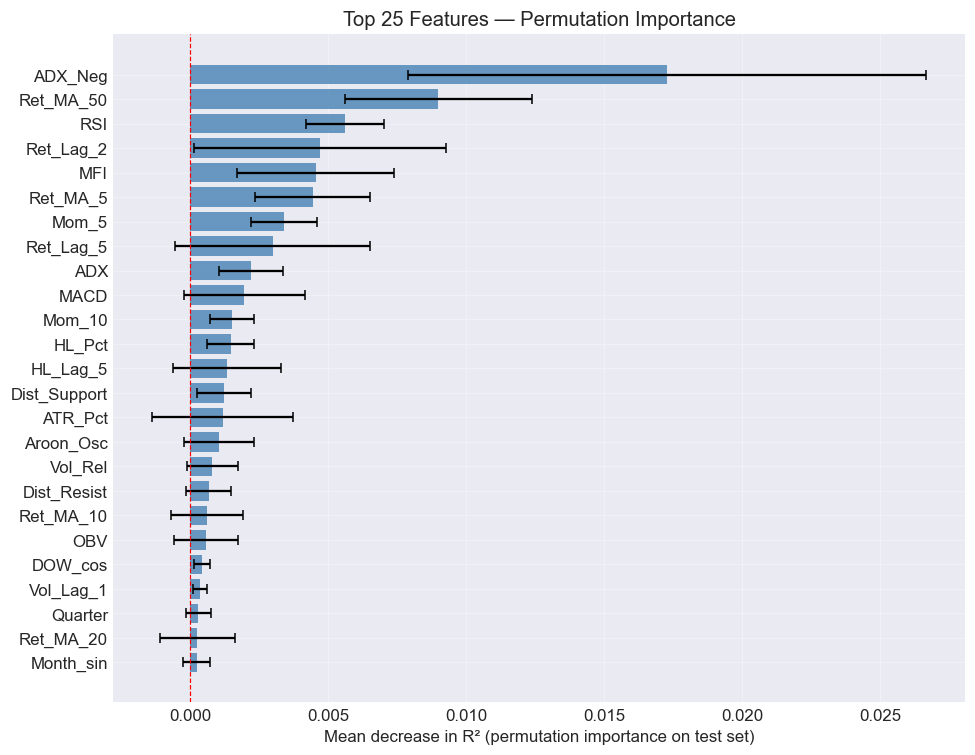

Selected 31 features with positive permutation importance
Dropped 32 features (negative importance)


In [5]:
# Initial RF for permutation importance — trees don't need scaling
rf_pi = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=5,
                               random_state=RANDOM_STATE, n_jobs=-1)
rf_pi.fit(X_train.values, y_train.values)

perm = permutation_importance(rf_pi, X_test.values, y_test.values,
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

pi_df = (pd.DataFrame({'Feature': X.columns,
                        'Importance': perm.importances_mean,
                        'Std': perm.importances_std})
           .sort_values('Importance', ascending=False)
           .reset_index(drop=True))

# Plot top 25
fig, ax = plt.subplots(figsize=(9, 7))
top25 = pi_df.head(25)
ax.barh(top25['Feature'][::-1], top25['Importance'][::-1],
        xerr=top25['Std'][::-1], capsize=3, color='steelblue', alpha=0.8)
ax.axvline(0, color='red', lw=0.8, linestyle='--')
ax.set_xlabel('Mean decrease in R² (permutation importance on test set)')
ax.set_title('Top 25 Features — Permutation Importance')
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Keep only features that are net-positive
SELECTED = pi_df[pi_df['Importance'] > 0]['Feature'].tolist()
if len(SELECTED) < 10:
    SELECTED = pi_df.head(20)['Feature'].tolist()  # fallback

print(f"Selected {len(SELECTED)} features with positive permutation importance")
print(f"Dropped {len(pi_df) - len(SELECTED)} features (negative importance)")

X_tr = X_train[SELECTED].values;  X_te = X_test[SELECTED].values
sc_sel = StandardScaler()
X_tr_sc = sc_sel.fit_transform(X_tr);  X_te_sc = sc_sel.transform(X_te)


## 5. Modeling

All models are trained on the selected feature set. Evaluation framework first, then models in increasing complexity.

**Primary metric:** direction accuracy (>50% = better than random; >52% = potentially tradeable).


In [6]:
# ── Evaluation utilities ─────────────────────────────────────────────────────
def metrics(y_true, y_pred, name=''):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    return {
        'Model':       name,
        'RMSE':        np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE':         mean_absolute_error(y_true, y_pred),
        'R2':          r2_score(y_true, y_pred),
        'Dir Acc (%)': np.mean(np.sign(y_true) == np.sign(y_pred)) * 100,
    }

def pprint(m):
    flag = '✅' if m['Dir Acc (%)'] > 52 else ('⚠️ ' if m['Dir Acc (%)'] > 50 else '❌')
    print(f"  {m['Model']:32}  DirAcc: {m['Dir Acc (%)']:.2f}%  {flag}  "
          f"RMSE: {m['RMSE']:.6f}  R²: {m['R2']:.4f}")

results = []

# ── Naive baseline: predict 0 (random walk) ───────────────────────────────────
naive = metrics(y_test, np.zeros(len(y_test)), 'Naive (predict 0)')
results.append(naive); pprint(naive)
print("  Every model must beat this to add value.\n")


  Naive (predict 0)                 DirAcc: 0.40%  ❌  RMSE: 0.018277  R²: -0.0001
  Every model must beat this to add value.



In [7]:
# ── Linear models (scaled input) ──────────────────────────────────────────────
print("Linear models:")
for name, mdl in [
    ('Linear Regression', LinearRegression()),
    ('Ridge (α=10)',       Ridge(alpha=10.0, random_state=RANDOM_STATE)),
    ('Lasso',              Lasso(alpha=1e-4, max_iter=10000, random_state=RANDOM_STATE)),
    ('ElasticNet',         ElasticNet(alpha=1e-3, l1_ratio=0.5, max_iter=10000, random_state=RANDOM_STATE)),
    ('Huber',              HuberRegressor(epsilon=1.35, alpha=1e-3, max_iter=300)),
]:
    mdl.fit(X_tr_sc, y_train)
    m = metrics(y_test, mdl.predict(X_te_sc), name)
    results.append(m); pprint(m)


Linear models:
  Linear Regression                 DirAcc: 49.40%  ❌  RMSE: 0.020694  R²: -0.2821
  Ridge (α=10)                      DirAcc: 50.20%  ⚠️   RMSE: 0.020092  R²: -0.2086
  Lasso                             DirAcc: 49.40%  ❌  RMSE: 0.019553  R²: -0.1446
  ElasticNet                        DirAcc: 48.40%  ❌  RMSE: 0.018556  R²: -0.0308
  Huber                             DirAcc: 48.80%  ❌  RMSE: 0.019416  R²: -0.1286


In [8]:
# ── Tree models (no scaling needed) ───────────────────────────────────────────
print("\nTree models:")
for name, mdl in [
    ('Random Forest',
        RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_leaf=5,
                               random_state=RANDOM_STATE, n_jobs=-1)),
    ('Gradient Boosting',
        GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                   min_samples_leaf=5, subsample=0.8,
                                   validation_fraction=0.1, n_iter_no_change=20,
                                   random_state=RANDOM_STATE)),
    ('XGBoost',
        XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                      min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
                      reg_alpha=0.1, reg_lambda=1.0,
                      random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)),
    ('LightGBM',
        LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31,
                       max_depth=6, min_child_samples=20,
                       subsample=0.8, colsample_bytree=0.8,
                       reg_alpha=0.1, reg_lambda=0.1,
                       random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)),
]:
    mdl.fit(X_tr, y_train)
    m = metrics(y_test, mdl.predict(X_te), name)
    results.append(m); pprint(m)



Tree models:
  Random Forest                     DirAcc: 51.80%  ⚠️   RMSE: 0.018290  R²: -0.0015
  Gradient Boosting                 DirAcc: 51.20%  ⚠️   RMSE: 0.018442  R²: -0.0183
  XGBoost                           DirAcc: 49.60%  ❌  RMSE: 0.018704  R²: -0.0473
  LightGBM                          DirAcc: 49.40%  ❌  RMSE: 0.018903  R²: -0.0698


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [9]:
# ── MLP (scaled input) ────────────────────────────────────────────────────────
print("\nNeural network:")
mlp = MLPRegressor(hidden_layer_sizes=(128, 64, 32), activation='relu',
                    solver='adam', alpha=1e-3, batch_size=64,
                    learning_rate='adaptive', learning_rate_init=1e-3,
                    max_iter=500, early_stopping=True, validation_fraction=0.1,
                    n_iter_no_change=15, random_state=RANDOM_STATE, verbose=False)
mlp.fit(X_tr_sc, y_train)
m = metrics(y_test, mlp.predict(X_te_sc), 'MLP')
results.append(m); pprint(m)



Neural network:
  MLP                               DirAcc: 51.00%  ⚠️   RMSE: 0.023276  R²: -0.6220


In [10]:
# ── Hyperparameter tuning (RandomizedSearchCV with TimeSeriesSplit) ───────────
print("\nTuning RF, XGBoost, LightGBM...")

searches = {
    'RF (Tuned)': (
        RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': randint(100, 400), 'max_depth': [5, 8, 10, 15, None],
         'min_samples_leaf': randint(2, 15), 'max_features': ['sqrt', 'log2', 0.5, 0.7]},
        X_tr, y_train, X_te
    ),
    'XGBoost (Tuned)': (
        XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
        {'n_estimators': randint(100, 400), 'max_depth': randint(3, 9),
         'learning_rate': loguniform(0.01, 0.2), 'subsample': uniform(0.6, 0.4),
         'colsample_bytree': uniform(0.6, 0.4), 'min_child_weight': randint(1, 10),
         'reg_alpha': loguniform(1e-4, 1), 'reg_lambda': loguniform(0.1, 10)},
        X_tr, y_train, X_te
    ),
    'LightGBM (Tuned)': (
        LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        {'n_estimators': randint(100, 500), 'learning_rate': loguniform(0.01, 0.2),
         'num_leaves': randint(15, 63), 'min_child_samples': randint(10, 50),
         'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.6, 0.4),
         'reg_alpha': loguniform(1e-4, 1), 'reg_lambda': loguniform(1e-4, 1)},
        X_tr, y_train, X_te
    ),
}

tuned_models = {}
for model_name, (estimator, param_dist, X_fit, y_fit, X_pred) in searches.items():
    rs = RandomizedSearchCV(estimator, param_dist, n_iter=30,
                             cv=TSCV, scoring='neg_root_mean_squared_error',
                             n_jobs=-1, random_state=RANDOM_STATE, verbose=0)
    rs.fit(X_fit, y_fit)
    tuned_models[model_name] = rs.best_estimator_
    m = metrics(y_test, rs.best_estimator_.predict(X_pred), model_name)
    results.append(m); pprint(m)
    print(f"    CV RMSE: {-rs.best_score_:.6f}  |  {rs.best_params_}")



Tuning RF, XGBoost, LightGBM...
  RF (Tuned)                        DirAcc: 53.20%  ✅  RMSE: 0.018321  R²: -0.0049
    CV RMSE: 0.020920  |  {'max_depth': 8, 'max_features': 'log2', 'min_samples_leaf': 13, 'n_estimators': 261}
  XGBoost (Tuned)                   DirAcc: 51.40%  ⚠️   RMSE: 0.018327  R²: -0.0055
    CV RMSE: 0.020638  |  {'colsample_bytree': np.float64(0.6557975442608167), 'learning_rate': np.float64(0.023993242906812727), 'max_depth': 8, 'min_child_weight': 3, 'n_estimators': 154, 'reg_alpha': np.float64(0.8568869785188996), 'reg_lambda': np.float64(0.85807606199213), 'subsample': np.float64(0.9439761626945282)}


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-

  LightGBM (Tuned)                  DirAcc: 51.40%  ⚠️   RMSE: 0.018328  R²: -0.0056
    CV RMSE: 0.020640  |  {'colsample_bytree': np.float64(0.9268888800804863), 'learning_rate': np.float64(0.05276341657158775), 'min_child_samples': 11, 'n_estimators': 484, 'num_leaves': 62, 'reg_alpha': np.float64(0.7272394089120152), 'reg_lambda': np.float64(0.017106998386865798), 'subsample': np.float64(0.9530545372757359)}


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [11]:
# ── Ensembles ─────────────────────────────────────────────────────────────────
print("\nEnsembles:")

xgb_tuned  = tuned_models['XGBoost (Tuned)']
lgbm_tuned = tuned_models['LightGBM (Tuned)']
rf_tuned   = tuned_models['RF (Tuned)']

# 1. Voting Regressor (equal-weight)
voting = VotingRegressor([
    ('ridge', Ridge(alpha=10.0, random_state=RANDOM_STATE)),
    ('rf',    RandomForestRegressor(**rf_tuned.get_params())),
    ('xgb',   XGBRegressor(**{**xgb_tuned.get_params(), 'verbosity': 0})),
    ('lgbm',  LGBMRegressor(**lgbm_tuned.get_params())),
])
voting.fit(X_tr, y_train)
m = metrics(y_test, voting.predict(X_te), 'Voting Ensemble')
results.append(m); pprint(m)

# 2. Manual time-series stacking
# StackingRegressor is INCOMPATIBLE with TimeSeriesSplit because TSS is not a
# true partition — early rows never appear in any validation fold.
# Solution: generate OOF predictions manually, train Ridge meta-learner on them.

base_models = {
    'ridge': Ridge(alpha=10.0, random_state=RANDOM_STATE),
    'rf':    RandomForestRegressor(**{**rf_tuned.get_params(), 'n_jobs': -1}),
    'xgb':   XGBRegressor(**{**xgb_tuned.get_params(), 'verbosity': 0}),
}
oof = {k: np.full(len(X_tr), np.nan) for k in base_models}

for tr_idx, val_idx in TimeSeriesSplit(n_splits=5).split(X_tr):
    sc_f = StandardScaler()
    Xf_tr_sc = sc_f.fit_transform(X_tr[tr_idx])
    Xf_val_sc = sc_f.transform(X_tr[val_idx])
    for k, mdl in base_models.items():
        m_ = clone(mdl)
        if k == 'ridge':
            m_.fit(Xf_tr_sc, y_train.values[tr_idx])
            oof[k][val_idx] = m_.predict(Xf_val_sc)
        else:
            m_.fit(X_tr[tr_idx], y_train.values[tr_idx])
            oof[k][val_idx] = m_.predict(X_tr[val_idx])

valid = ~np.isnan(next(iter(oof.values())))
meta = Ridge(alpha=1.0, random_state=RANDOM_STATE)
meta.fit(np.column_stack([oof[k][valid] for k in base_models]), y_train.values[valid])

# Re-fit base models on full train set, generate test predictions
test_cols = []
for k, mdl in base_models.items():
    m_ = clone(mdl)
    if k == 'ridge':
        m_.fit(X_tr_sc, y_train.values)
        test_cols.append(m_.predict(X_te_sc))
    else:
        m_.fit(X_tr, y_train.values)
        test_cols.append(m_.predict(X_te))

y_stacked = meta.predict(np.column_stack(test_cols))
m = metrics(y_test, y_stacked, 'TSS Stacking')
results.append(m); pprint(m)

# 3. OOF-weighted average (weights from CV RMSE — no test-set leakage)
oof_rmse = {}
for k, mdl in {'Ridge': Ridge(alpha=10.0), 'XGBoost': xgb_tuned, 'LightGBM': lgbm_tuned}.items():
    cv_scores = cross_val_score(mdl, X_tr, y_train, cv=TSCV,
                                 scoring='neg_root_mean_squared_error', n_jobs=-1)
    oof_rmse[k] = -cv_scores.mean()

raw_w = {k: 1.0/v for k, v in oof_rmse.items()}
w = {k: v/sum(raw_w.values()) for k, v in raw_w.items()}
print(f"  Ensemble weights: {', '.join(f'{k}:{v:.3f}' for k,v in w.items())}")

ens_preds = {}
for k, mdl in {'Ridge': Ridge(alpha=10.0), 'XGBoost': xgb_tuned, 'LightGBM': lgbm_tuned}.items():
    mdl.fit(X_tr, y_train)
    ens_preds[k] = mdl.predict(X_te)

y_weighted = sum(w[k] * ens_preds[k] for k in w)
m = metrics(y_test, y_weighted, 'Weighted Ensemble (OOF)')
results.append(m); pprint(m)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=4.3153e-21): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T



Ensembles:


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  Voting Ensemble                   DirAcc: 51.20%  ⚠️   RMSE: 0.018450  R²: -0.0191
  TSS Stacking                      DirAcc: 51.40%  ⚠️   RMSE: 0.018334  R²: -0.0064


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=9.73125e-20): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=4.3038e-20): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=2.33498e-20): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=1.24159e-20): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_ridge.p

  Ensemble weights: Ridge:0.266, XGBoost:0.367, LightGBM:0.367
  Weighted Ensemble (OOF)           DirAcc: 51.40%  ⚠️   RMSE: 0.018491  R²: -0.0237


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


## 6. Evaluation

Walk-forward cross-validation (expanding window) gives a more honest picture than a single train/test split — it simulates production retraining across different market regimes.


MODEL COMPARISON  (sorted by direction accuracy)
                  Model    RMSE     MAE       R2  Dir Acc (%)
             RF (Tuned) 0.01832 0.01365 -0.00490     53.20000
          Random Forest 0.01829 0.01367 -0.00155     51.80000
Weighted Ensemble (OOF) 0.01849 0.01372 -0.02368     51.40000
           TSS Stacking 0.01833 0.01360 -0.00636     51.40000
       LightGBM (Tuned) 0.01833 0.01360 -0.00564     51.40000
        XGBoost (Tuned) 0.01833 0.01359 -0.00555     51.40000
        Voting Ensemble 0.01845 0.01371 -0.01910     51.20000
      Gradient Boosting 0.01844 0.01377 -0.01827     51.20000
                    MLP 0.02328 0.01806 -0.62197     51.00000
           Ridge (α=10) 0.02009 0.01534 -0.20857     50.20000
                XGBoost 0.01870 0.01385 -0.04735     49.60000
               LightGBM 0.01890 0.01427 -0.06979     49.40000
      Linear Regression 0.02069 0.01587 -0.28211     49.40000
                  Lasso 0.01955 0.01486 -0.14461     49.40000
                  Hub

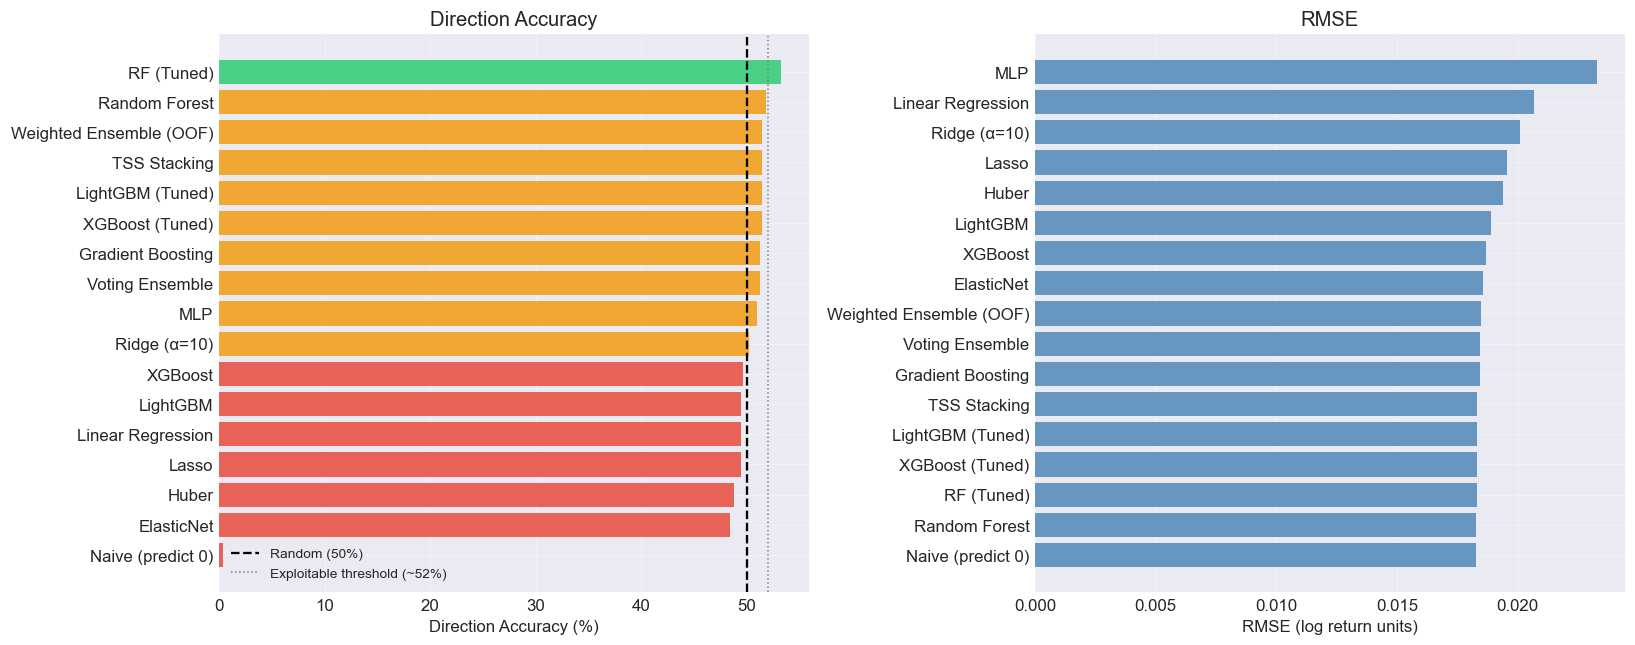


🏆 Best model: RF (Tuned)  |  Dir Acc: 53.20%


In [12]:
# ── Model comparison table ────────────────────────────────────────────────────
results_df = pd.DataFrame(results).sort_values('Dir Acc (%)', ascending=False)
print("=" * 75)
print("MODEL COMPARISON  (sorted by direction accuracy)")
print("=" * 75)
print(results_df.to_string(index=False, float_format='{:.5f}'.format))

# Visual comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sorted_da = results_df.sort_values('Dir Acc (%)')
colors = ['#2ecc71' if v > 52 else ('#f39c12' if v > 50 else '#e74c3c') for v in sorted_da['Dir Acc (%)']]
ax1.barh(sorted_da['Model'], sorted_da['Dir Acc (%)'], color=colors, alpha=0.85)
ax1.axvline(50, color='black', linestyle='--', lw=1.5, label='Random (50%)')
ax1.axvline(52, color='gray', linestyle=':', lw=1, label='Exploitable threshold (~52%)')
ax1.set_xlabel('Direction Accuracy (%)'); ax1.set_title('Direction Accuracy')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

sorted_rmse = results_df.sort_values('RMSE')
ax2.barh(sorted_rmse['Model'], sorted_rmse['RMSE'], color='steelblue', alpha=0.8)
ax2.set_xlabel('RMSE (log return units)'); ax2.set_title('RMSE')
ax2.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

best_row = results_df.iloc[0]
print(f"\n🏆 Best model: {best_row['Model']}  |  Dir Acc: {best_row['Dir Acc (%)']:.2f}%")


In [13]:
# ── Walk-forward cross-validation ─────────────────────────────────────────────
print("Walk-forward CV (expanding window, 5 folds)...")

wf_models = {
    'Ridge':   Ridge(alpha=10.0, random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(**{**xgb_tuned.get_params(), 'verbosity': 0}),
    'LGBM':    LGBMRegressor(**lgbm_tuned.get_params()),
    'GBM':     GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                          max_depth=4, random_state=RANDOM_STATE),
}
wf_rmse = {k: [] for k in wf_models}
wf_da   = {k: [] for k in wf_models}

for tr_idx, val_idx in TimeSeriesSplit(n_splits=5, gap=5).split(X.values):
    Xw_tr, Xw_val = X.values[tr_idx], X.values[val_idx]
    yw_tr, yw_val = y.values[tr_idx], y.values[val_idx]
    sc_w = StandardScaler()
    Xw_tr_sc, Xw_val_sc = sc_w.fit_transform(Xw_tr), sc_w.transform(Xw_val)

    for k, mdl in wf_models.items():
        m_ = clone(mdl)
        Xf, Xv = (Xw_tr_sc, Xw_val_sc) if k == 'Ridge' else (Xw_tr, Xw_val)
        m_.fit(Xf, yw_tr)
        preds = m_.predict(Xv)
        wf_rmse[k].append(np.sqrt(mean_squared_error(yw_val, preds)))
        wf_da[k].append(np.mean(np.sign(yw_val) == np.sign(preds)) * 100)

print("\n" + "=" * 60)
print("WALK-FORWARD RESULTS  (mean ± std across 5 folds)")
print("=" * 60)
for k in wf_models:
    print(f"  {k:12}  RMSE: {np.mean(wf_rmse[k]):.6f} ± {np.std(wf_rmse[k]):.6f}  "
          f"Dir Acc: {np.mean(wf_da[k]):.2f}% ± {np.std(wf_da[k]):.2f}%")


Walk-forward CV (expanding window, 5 folds)...


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



WALK-FORWARD RESULTS  (mean ± std across 5 folds)
  Ridge         RMSE: 0.026991 ± 0.009735  Dir Acc: 50.70% ± 2.49%
  XGBoost       RMSE: 0.019172 ± 0.006483  Dir Acc: 49.79% ± 3.73%
  LGBM          RMSE: 0.019172 ± 0.006477  Dir Acc: 49.47% ± 3.75%
  GBM           RMSE: 0.025836 ± 0.007621  Dir Acc: 47.00% ± 3.86%


## 7. Trading Strategy Backtest

Simple long-only strategy: enter when predicted return exceeds a threshold.

- **Transaction cost:** 0.1% round-trip (applied on every position change)
- **Metrics:** annualised Sharpe, Sortino, max drawdown, win rate


Using: RF (Tuned)

Metric                       Buy & Hold     Strategy
----------------------------------------------------
Total Return (%)                  6.99%        7.46%
Annualised Sharpe                  0.12         0.13
Sortino Ratio                         —         0.18
Max Drawdown (%)                 30.02%       33.49%
Win Rate (active days)                —        51.6%
Days in market                      500          490
Number of trades                      —           19


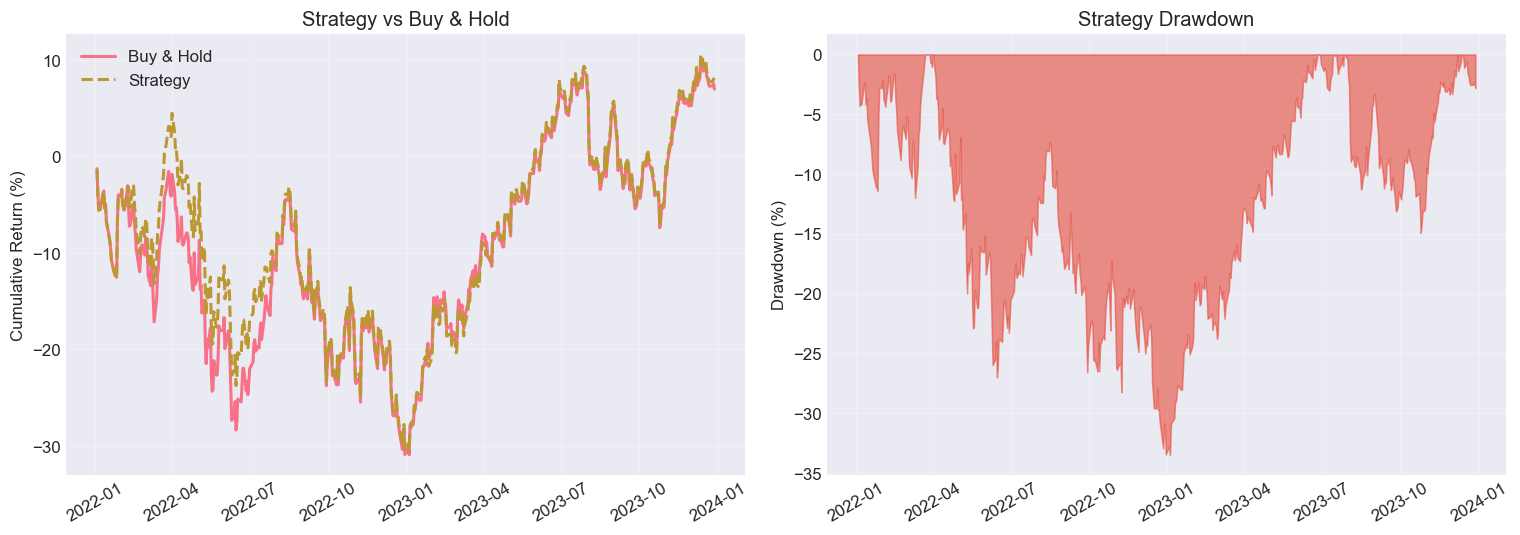

In [14]:
# Use best model from results table
SIGNAL_THRESHOLD = 0.001   # only trade when predicted return > 0.1%
TC               = 0.001   # 0.1% round-trip transaction cost

# Reconstruct best model predictions
best_name = results_df.iloc[0]['Model']
print(f"Using: {best_name}")

# Weighted ensemble is a safe default; replace with best_model.predict() if stored
y_pred_bt = y_weighted  # swap for any model's test predictions

signals          = np.where(y_pred_bt > SIGNAL_THRESHOLD, 1, 0)
strategy_returns = y_test.values * signals
strategy_returns -= np.abs(np.diff(signals, prepend=0)) * TC  # deduct cost on changes

# Cumulative wealth
cum_bnh  = np.exp(np.cumsum(y_test.values)) - 1
cum_strat = np.exp(np.cumsum(strategy_returns)) - 1

# ── Risk metrics (annualised) ──────────────────────────────────────────────────
def sharpe(r, ann=252):
    return (r.mean() / r.std()) * np.sqrt(ann) if r.std() > 0 else 0.0

def sortino(r, ann=252):
    dd = r[r < 0].std()
    return (r.mean() / dd) * np.sqrt(ann) if dd > 0 else 0.0

def max_dd(cum_r):
    w = 1 + cum_r
    return ((np.maximum.accumulate(w) - w) / np.maximum.accumulate(w)).max()

active = strategy_returns[signals == 1]
win_rate = np.mean(active > 0) * 100 if len(active) > 0 else 0.0

print(f"\n{'Metric':<26} {'Buy & Hold':>12} {'Strategy':>12}")
print("-" * 52)
print(f"{'Total Return (%)':<26} {cum_bnh[-1]*100:>11.2f}% {cum_strat[-1]*100:>11.2f}%")
print(f"{'Annualised Sharpe':<26} {sharpe(y_test.values):>12.2f} {sharpe(strategy_returns):>12.2f}")
print(f"{'Sortino Ratio':<26} {'—':>12} {sortino(strategy_returns):>12.2f}")
print(f"{'Max Drawdown (%)':<26} {max_dd(cum_bnh)*100:>11.2f}% {max_dd(cum_strat)*100:>11.2f}%")
print(f"{'Win Rate (active days)':<26} {'—':>12} {win_rate:>11.1f}%")
print(f"{'Days in market':<26} {len(signals):>12} {signals.sum():>12}")
print(f"{'Number of trades':<26} {'—':>12} {int(np.abs(np.diff(signals, prepend=0)).sum()):>12}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
test_dates = X_test.index

axes[0].plot(test_dates, cum_bnh * 100, label='Buy & Hold', lw=2)
axes[0].plot(test_dates, cum_strat * 100, label='Strategy', lw=2, linestyle='--')
axes[0].set_ylabel('Cumulative Return (%)'); axes[0].set_title('Strategy vs Buy & Hold')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[0].tick_params(axis='x', rotation=30)

wealth = 1 + cum_strat
peak   = np.maximum.accumulate(wealth)
dd_pct = (wealth - peak) / peak * 100
axes[1].fill_between(test_dates, dd_pct, 0, alpha=0.6, color='#e74c3c')
axes[1].set_ylabel('Drawdown (%)'); axes[1].set_title('Strategy Drawdown')
axes[1].grid(True, alpha=0.3)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout(); plt.show()
